# Loan Cohort Analysis: LoanType and RemainingTerm

Build interpretable, CPR-homogeneous cohorts from pooled monthly loan tapes. Each row uses its own snapshot Market_Rate to calculate RateSpread = IntRate - Market_Rate.

This version replaces investor-derived model/rule features with normalized LoanType, removes LoanAge, and evaluates RemainingTerm before adding the requested 240/360-month term bands. Other numeric and categorical candidates are evaluated by shallow regression trees; material drivers guide the business rules.

The notebook loads and filters the tapes, analyzes drivers, fits depth-4/depth-6 trees, evaluates term significance with held-out loans, constructs and merges business rules, validates assignment and fit, reports training-period stability, exports a versioned scoring schema, and sweeps merge parameters.

Metrics and figures are recomputed from the loaded data. Snapshot observations may repeat the same loan: held-out evaluation groups by LoanNum, while descriptive SE and UPB statistics remain pooled-observation measures.

In [51]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, export_text

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

# ---- Training data: one or more loan-tape snapshots, pooled together ---------------------
# Each file already carries its own `Market_Rate` column (the market rate in effect as of that
# snapshot date), so RateSpread = IntRate - Market_Rate is computed PER LOAN, PER PERIOD from
# the data itself -- there is no single global MARKET_RATE constant to keep in sync anymore.
TRAIN_SRCS = [
    #"LL_Pricing_03312026_Enriched.csv",
    #"LL_Pricing_04302026_Enriched.csv",
    "LL_Pricing_06302026_Enriched.csv",
    "LL_Pricing_07312026_Enriched.csv",
]

# ---- Business parameters (tune these) -----------------------------------------------------
# v2 uses a reliability-of-estimate merge trigger instead of a hard N floor:
#   1. SE_MEAN_TARGET     - a cohort is "reliable" when its standard error of the mean
#                           CPR (Std_CPR / sqrt(N)) is at or below this many CPR points.
#                           Merge continues until every cohort clears this bar (or no
#                           merge is available that doesn't inflate std too much).
#   2. STD_INFLATION_MAX  - a merge is REJECTED when the pooled std would exceed the
#                           tighter constituent's std by more than this factor.
#   3. MIN_COHORT_N_FLOOR - hard absolute-floor safety net. Cohorts below this always
#                           get force-merged, and force-merges bypass the inflation
#                           guard so tiny/empty bands can always be absorbed for full
#                           feature-space coverage.
#   4. MEAN_MERGE_TOL     - kept as a mild similarity trigger: merge adjacent cohorts
#                           whose means are within this many CPR points.
SE_MEAN_TARGET = 0.25
STD_INFLATION_MAX = 1.20
MIN_COHORT_N_FLOOR = 1500
MEAN_MERGE_TOL = 0.5
CV_FLAG_THRESHOLD = 0.25  # secondary flag: cohort std is >=35% of the mean


## 1. Load, Clean & Pool the Training Snapshots

The raw tape has known sentinel/outlier values that would distort statistics if left as-is:
- `FICOOrig`: values `<=300` or `>=850` are not real scores (missing codes).
- `LTVOrig`: expressed as a ratio (0.983 = 98.3%); values `<=0` or `>150%` are data errors.
- `RemainingTerm`: a small number of negative values (loan past scheduled maturity but still active).

These are set to `NaN` (not dropped), and we restrict to **active** loans
(`PaidOff_Flag_ADM == 0`) — a `PaidOff_Flag_ADM` of `0` means the loan is still active (NOT
paid off); `1` means paid off. We only drop the paid-off (`==1`) rows, since a payoff-model CPR
for an already-paid-off loan isn't meaningful going forward.

Each snapshot file is tagged with its own `Period` (parsed from the filename) and keeps its own
`Market_Rate` column, so `RateSpread` always reflects the correct refinance incentive **for that
snapshot's rate environment** — a loan sitting at the same `IntRate` can be in- or out-of-the-money
depending on which month it's observed in.


In [52]:
RAW_COLS = [
    "LoanNum", "LTVOrig", "FICOOrig", "InvestorCatgy", "LoanType", "ArmFlag",
    "RemainingTerm", "PrinBal", "IntRate", "ModelCPR", "PaidOff_Flag_ADM",
    "Market_Rate", "SellerName",
]


def normalize_loan_type(values):
    values = values.astype("string").str.strip().str.upper().replace({"CONV-PMI": "CONV"})
    return values.where(values.isin(["CONV", "FHA", "VA"]), "OTHERS")


def _period_label(path):
    match = re.search(r"(\d{2})(\d{2})(\d{4})", path)
    mm, dd, yyyy = match.groups()
    return f"{yyyy}-{mm}-{dd}"


def load_clean(path):
    data = pd.read_csv(path, usecols=RAW_COLS, dtype={"LoanType": "string"}, low_memory=False)
    data = data.loc[data["PaidOff_Flag_ADM"].eq(0)].drop(columns="PaidOff_Flag_ADM").copy()
    data.loc[(data["FICOOrig"] <= 300) | (data["FICOOrig"] >= 850), "FICOOrig"] = np.nan
    data.loc[(data["LTVOrig"] <= 0) | (data["LTVOrig"] > 1.5), "LTVOrig"] = np.nan
    data.loc[data["RemainingTerm"] < 0, "RemainingTerm"] = np.nan
    data["ArmFlag"] = data["ArmFlag"].astype(int)
    data["LoanType"] = normalize_loan_type(data["LoanType"])
    data["RateSpread"] = data["IntRate"] - data["Market_Rate"]
    data["Period"] = _period_label(path)
    data["SourceFile"] = path
    return data


df = pd.concat([load_clean(path) for path in TRAIN_SRCS], ignore_index=True)
period_summary = df.groupby("Period").agg(
    Loans=("ModelCPR", "count"), Market_Rate=("Market_Rate", "first"),
    Mean_ModelCPR=("ModelCPR", "mean"), Std_ModelCPR=("ModelCPR", "std")
).reset_index()
n_distinct_loans = df["LoanNum"].nunique()
n_repeat_obs = len(df) - n_distinct_loans
print(f"Training snapshots pooled: {len(TRAIN_SRCS)}")
print(period_summary.round(3).to_string(index=False))
print(f"Active-loan observations: {len(df):,}; distinct loans: {n_distinct_loans:,}")
print(f"Repeat monthly observations: {n_repeat_obs:,} ({n_repeat_obs / len(df):.1%})")
display(df.groupby(["Period", "LoanType"], observed=True).size().unstack(fill_value=0))
df.head()

Training snapshots pooled: 2
    Period  Loans  Market_Rate  Mean_ModelCPR  Std_ModelCPR
2026-06-30 827837        6.490          6.040         4.883
2026-07-31 818443        6.542          5.448         3.789
Active-loan observations: 1,646,280; distinct loans: 846,297
Repeat monthly observations: 799,983 (48.6%)


LoanType,CONV,FHA,OTHERS,VA
Period,,,,
2026-06-30,697635,85138,3098,41966
2026-07-31,682583,86783,3173,45904


,LoanNum,IntRate,ModelCPR,LTVOrig,FICOOrig,InvestorCatgy,ArmFlag,RemainingTerm,PrinBal,LoanType,SellerName,Market_Rate,RateSpread,Period,SourceFile
0,87064,4.125,3.747917,0.983,572.0,PLS,0,234.0,113115.30,FHA,NaN,6.49,-2.365,2026-06-30,LL_Pricing_06302026_Enriched.csv
1,113225,7.125,5.352098,1.040,607.0,PLS,0,29.0,424.10,CONV,NaN,6.49,0.635,2026-06-30,LL_Pricing_06302026_Enriched.csv
2,128900,6.125,6.161238,0.565,682.0,FNMA,0,29.0,12394.50,CONV,NaN,6.49,-0.365,2026-06-30,LL_Pricing_06302026_Enriched.csv
3,170258,6.625,6.755850,0.988,638.0,PLS,0,347.0,29124.06,FHA,NaN,6.49,0.135,2026-06-30,LL_Pricing_06302026_Enriched.csv
4,216515,6.500,8.081242,1.010,558.0,PLS,0,30.0,5934.62,FHA,NaN,6.49,0.010,2026-06-30,LL_Pricing_06302026_Enriched.csv


In [53]:
# Drop PLS Loans from the dataset
df = df[df["InvestorCatgy"] != "PLS"].copy()

In [54]:
assert normalize_loan_type(pd.Series(["CONV", "CONV-PMI", "FHA", "VA", "USDA", None, ""])).tolist() == [
    "CONV", "CONV", "FHA", "VA", "OTHERS", "OTHERS", "OTHERS"
]
assert df["LoanType"].isin(["CONV", "FHA", "VA", "OTHERS"]).all()
print("LoanType normalization checks passed.")

LoanType normalization checks passed.


In [55]:
# Drop the SellerName where it is Ocwen, OCWEN REO or NULL OR BLANK OR NaN or UNKNOWN

from matplotlib.pylab import NaN


df = df[~df["SellerName"].isin(["OCWEN", "OCWEN REO", None, NaN, "UNKNOWN", ""] )].copy()

n_distinct_loans = df["LoanNum"].nunique()
n_repeat_obs = len(df) - n_distinct_loans

print(f"\nTotal active-loan observations pooled: {len(df):,}")
print(f"Distinct loans (by LoanNum):            {n_distinct_loans:,}")


Total active-loan observations pooled: 1,210,118
Distinct loans (by LoanNum):            626,132


## 2. Driver Analysis — Which Characteristics Actually Explain `ModelCPR`?

We check how much variance each candidate driver explains via correlation, and confirm the same
drivers matter **consistently in every training period** (not just on average) — a first,
simple stability check before any cohort rules are built.


In [56]:
FEATURES_NUM = ["RateSpread", "LTVOrig", "FICOOrig", "RemainingTerm", "PrinBal"]
FEATURES_CAT = ["LoanType", "ArmFlag"]
IMPORTANCE_THRESHOLD = 0.005

print("Missing values per numeric feature:")
print(df[FEATURES_NUM].isna().sum())
corrs = df[FEATURES_NUM + ["ModelCPR"]].corr()["ModelCPR"].drop("ModelCPR")
display(corrs.sort_values(key=abs, ascending=False))
by_period_corr = pd.DataFrame({
    period: group[FEATURES_NUM + ["ModelCPR"]].corr()["ModelCPR"].drop("ModelCPR")
    for period, group in df.groupby("Period")
}).T
print("Numeric correlations by training period:")
display(by_period_corr.round(3))

Missing values per numeric feature:
RateSpread           0
LTVOrig            552
FICOOrig         66214
RemainingTerm        2
PrinBal              0
dtype: int64


RateSpread       0.720376
RemainingTerm    0.356597
PrinBal          0.255681
FICOOrig         0.033012
LTVOrig          0.012498
Name: ModelCPR, dtype: float64

Numeric correlations by training period:


,RateSpread,LTVOrig,FICOOrig,RemainingTerm,PrinBal
2026-06-30,0.741,0.020,0.031,0.369,0.270
2026-07-31,0.717,0.005,0.035,0.353,0.246


In [57]:
print("Mean ModelCPR by ArmFlag:")
display(df.groupby("ArmFlag")["ModelCPR"].agg(["count", "mean", "std"]))
print("Mean ModelCPR by normalized LoanType:")
display(df.groupby("LoanType")["ModelCPR"].agg(["count", "mean", "std"]))

Mean ModelCPR by ArmFlag:


,count,mean,std
ArmFlag,,,
0,1207816,6.217075,4.604316
1,2302,18.762883,7.783829


Mean ModelCPR by normalized LoanType:


,count,mean,std
LoanType,,,
CONV,1030967,6.147296,4.150496
FHA,105608,6.408056,6.888356
OTHERS,5884,2.767019,2.704526
VA,67659,7.709141,6.728946


## 3. Refinance Incentive: `ModelCPR` vs. Rate Spread

`RateSpread = IntRate - Market_Rate` measures how "in the money" (positive) or "out of the
money" (negative) a borrower is to refinance, using **that loan's own snapshot's market rate**.
This is expected to be one of the strongest prepayment drivers. We profile `ModelCPR` mean & std
in fine, fixed-width bins (pooled), and then check the same "smile" shape holds up **separately
in each training period** — if the shape is consistent across different rate environments, that's
direct evidence the driver is real and not a one-month artifact.


In [58]:
def rate_spread_profile(data, bin_width=0.25, lo=-3.0, hi=4.0):
    work = data.dropna(subset=["RateSpread", "ModelCPR"]).copy()
    edges = np.arange(lo, hi + bin_width, bin_width)
    work["SpreadBin"] = pd.cut(work["RateSpread"], bins=edges)
    prof = work.groupby("SpreadBin", observed=True)["ModelCPR"].agg(["count", "mean", "std"])
    prof["cv"] = prof["std"] / prof["mean"]
    return prof


profile_fine = rate_spread_profile(df, bin_width=0.25, lo=-5.0, hi=6.0)
profile_fine


,count,mean,std,cv
SpreadBin,,,,
"(-5.0, -4.75]",111,2.853601,0.587259,0.205796
"(-4.75, -4.5]",1850,3.122503,0.773165,0.247611
"(-4.5, -4.25]",8193,3.096793,0.883362,0.285251
"(-4.25, -4.0]",36727,3.221838,0.717024,0.222551
"(-4.0, -3.75]",105211,3.374946,0.569284,0.168679
"(-3.75, -3.5]",164080,3.425476,0.556950,0.162591
"(-3.5, -3.25]",80332,3.263454,0.700976,0.214796
"(-3.25, -3.0]",62644,3.291037,0.861559,0.261790
"(-3.0, -2.75]",34997,3.227029,1.254012,0.388596


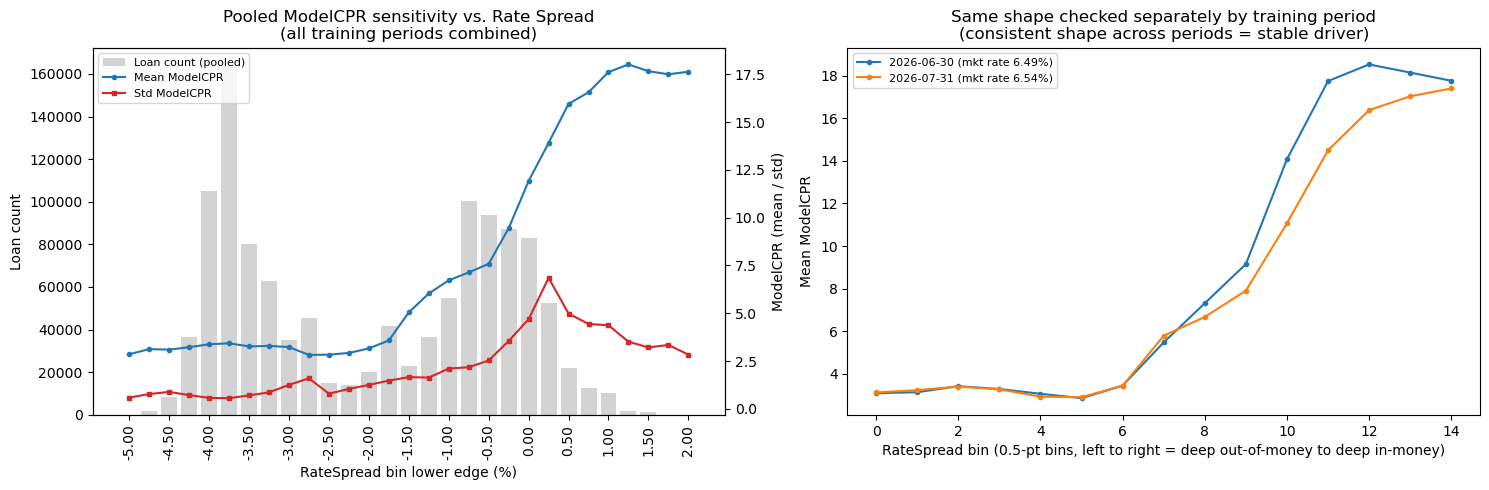

Peak mean-CPR RateSpread bin (pooled): (1.25, 1.5]


In [59]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

x = np.arange(len(profile_fine))
labels = [f"{iv.left:.2f}" for iv in profile_fine.index]
ax1.bar(x, profile_fine["count"], color="lightgray", label="Loan count (pooled)")
ax1.set_ylabel("Loan count")
ax1.set_xticks(x[::2])
ax1.set_xticklabels(labels[::2], rotation=90)
ax1.set_xlabel("RateSpread bin lower edge (%)")
ax1b = ax1.twinx()
ax1b.plot(x, profile_fine["mean"], color="tab:blue", marker="o", markersize=3, label="Mean ModelCPR")
ax1b.plot(x, profile_fine["std"], color="tab:red", marker="s", markersize=3, label="Std ModelCPR")
ax1b.set_ylabel("ModelCPR (mean / std)")
l1, lb1 = ax1.get_legend_handles_labels()
l2, lb2 = ax1b.get_legend_handles_labels()
ax1b.legend(l1 + l2, lb1 + lb2, loc="upper left", fontsize=8)
ax1.set_title("Pooled ModelCPR sensitivity vs. Rate Spread\n(all training periods combined)")

for period, g in df.groupby("Period"):
    prof_p = rate_spread_profile(g, bin_width=0.5, lo=-5.0, hi=5.0)
    xp = np.arange(len(prof_p))
    mkt = g["Market_Rate"].iloc[0]
    ax2.plot(xp, prof_p["mean"], marker="o", markersize=3, label=f"{period} (mkt rate {mkt:.2f}%)")
ax2.set_xlabel("RateSpread bin (0.5-pt bins, left to right = deep out-of-money to deep in-money)")
ax2.set_ylabel("Mean ModelCPR")
ax2.set_title("Same shape checked separately by training period\n(consistent shape across periods = stable driver)")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

peak_bin = profile_fine["mean"].idxmax()
print(f"Peak mean-CPR RateSpread bin (pooled): {peak_bin}")



## 4. Confirm With a Shallow, Interpretable Decision Tree

A depth-limited CART regression tree picks the splits that reduce `ModelCPR` variance the most —
a data-driven, non-parametric way to sanity-check which variables matter (including interactions
correlation would miss), re-run here on the pooled multi-period data. We keep it shallow
(depth 4-6) so the resulting splits stay simple enough to translate into business rules.


In [60]:
def fit_tree(data, max_depth=4, min_leaf_frac=0.02, verbose=True):
    work = data.dropna(subset=FEATURES_NUM + ["ModelCPR"]).copy()
    features = pd.concat([
        work[FEATURES_NUM + ["ArmFlag"]],
        pd.get_dummies(work["LoanType"], prefix="LoanType", dtype=int)
    ], axis=1)
    target = work["ModelCPR"]
    min_leaf = max(200, int(len(work) * min_leaf_frac))
    tree = DecisionTreeRegressor(max_depth=max_depth, min_samples_leaf=min_leaf, random_state=42)
    tree.fit(features, target)
    assert not any("Investor" in name or "LoanAge" in name for name in features.columns)
    if verbose:
        importance = pd.Series(tree.feature_importances_, index=features.columns).sort_values(ascending=False)
        print(f"Tree: {len(work):,} rows; min_samples_leaf={min_leaf:,}; max_depth={max_depth}")
        print(importance.to_string())
        print(export_text(tree, feature_names=list(features.columns), show_weights=True))
        print(f"Training R^2: {tree.score(features, target):.4f}")
    return tree, features, target


tree_depth4, X_depth4, y_depth4 = fit_tree(df, max_depth=4)

Tree: 1,143,566 rows; min_samples_leaf=22,871; max_depth=4
RateSpread         0.932047
RemainingTerm      0.040558
PrinBal            0.022812
LoanType_CONV      0.004582
LTVOrig            0.000000
FICOOrig           0.000000
ArmFlag            0.000000
LoanType_FHA       0.000000
LoanType_OTHERS    0.000000
LoanType_VA        0.000000
|--- RateSpread <= -0.17
|   |--- RateSpread <= -1.38
|   |   |--- LoanType_CONV <= 0.50
|   |   |   |--- RateSpread <= -2.50
|   |   |   |   |--- value: [1.62]
|   |   |   |--- RateSpread >  -2.50
|   |   |   |   |--- value: [2.87]
|   |   |--- LoanType_CONV >  0.50
|   |   |   |--- RemainingTerm <= 311.50
|   |   |   |   |--- value: [3.37]
|   |   |   |--- RemainingTerm >  311.50
|   |   |   |   |--- value: [4.94]
|   |--- RateSpread >  -1.38
|   |   |--- RemainingTerm <= 355.50
|   |   |   |--- RateSpread <= -0.41
|   |   |   |   |--- value: [7.22]
|   |   |   |--- RateSpread >  -0.41
|   |   |   |   |--- value: [9.09]
|   |   |--- RemainingTerm >  3

In [61]:
df[FEATURES_NUM + ["ArmFlag"]].corrwith(df["ModelCPR"])

RateSpread       0.720376
LTVOrig          0.012498
FICOOrig         0.033012
RemainingTerm    0.356597
PrinBal          0.255681
ArmFlag          0.117697
dtype: float64

In [62]:
tree4, X4, y4 = fit_tree(df, max_depth=6)


Tree: 1,143,566 rows; min_samples_leaf=22,871; max_depth=6
RateSpread         0.926858
RemainingTerm      0.040689
PrinBal            0.025299
LoanType_CONV      0.006604
LTVOrig            0.000551
FICOOrig           0.000000
ArmFlag            0.000000
LoanType_FHA       0.000000
LoanType_OTHERS    0.000000
LoanType_VA        0.000000
|--- RateSpread <= -0.17
|   |--- RateSpread <= -1.38
|   |   |--- LoanType_CONV <= 0.50
|   |   |   |--- RateSpread <= -2.50
|   |   |   |   |--- value: [1.62]
|   |   |   |--- RateSpread >  -2.50
|   |   |   |   |--- value: [2.87]
|   |   |--- LoanType_CONV >  0.50
|   |   |   |--- RemainingTerm <= 311.50
|   |   |   |   |--- RemainingTerm <= 250.50
|   |   |   |   |   |--- RemainingTerm <= 108.50
|   |   |   |   |   |   |--- value: [3.48]
|   |   |   |   |   |--- RemainingTerm >  108.50
|   |   |   |   |   |   |--- value: [3.03]
|   |   |   |   |--- RemainingTerm >  250.50
|   |   |   |   |   |--- RateSpread <= -2.55
|   |   |   |   |   |   |--- valu

In [67]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import r2_score

imp6 = pd.Series(tree4.feature_importances_, index=X4.columns).sort_values(ascending=False)
material = imp6[imp6 > IMPORTANCE_THRESHOLD]
immaterial = imp6[imp6 <= IMPORTANCE_THRESHOLD]
print(f"Material drivers (>{IMPORTANCE_THRESHOLD:.1%} importance): {list(material.index)}")
print(f"Below threshold: {list(immaterial.index)}")
period_importance = {}
for period, group in df.groupby("Period"):
    period_tree, period_features, _ = fit_tree(group, max_depth=6, verbose=False)
    period_importance[period] = pd.Series(period_tree.feature_importances_, index=period_features.columns)
period_importance = pd.DataFrame(period_importance).T.fillna(0)
display(period_importance.round(4))

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(splitter.split(X4, y4, groups=df.loc[X4.index, "LoanNum"]))
assert set(df.loc[X4.index[train_idx], "LoanNum"]).isdisjoint(df.loc[X4.index[test_idx], "LoanNum"])
heldout_models = {}
for name, columns in {"with_term": list(X4.columns), "without_term": list(X4.drop(columns="RemainingTerm").columns)}.items():
    model = DecisionTreeRegressor(max_depth=6, min_samples_leaf=max(200, int(len(train_idx) * 0.02)), random_state=42)
    model.fit(X4.iloc[train_idx][columns], y4.iloc[train_idx])
    heldout_models[name] = (model, columns)
term_ablation = pd.DataFrame([
    {"Period": period, **{
        name: r2_score(y4.loc[index], model.predict(X4.loc[index, columns]))
        for name, (model, columns) in heldout_models.items()
    }}
    for period, group in df.loc[X4.index[test_idx]].groupby("Period")
    for index in [group.index]
]).set_index("Period")
term_ablation["R2_gain"] = term_ablation["with_term"] - term_ablation["without_term"]
display(term_ablation.round(4))
USE_REMAINING_TERM = bool(
    imp6["RemainingTerm"] > IMPORTANCE_THRESHOLD
    and period_importance["RemainingTerm"].gt(IMPORTANCE_THRESHOLD).all()
    and term_ablation["R2_gain"].gt(0).all()
)
print(f"RemainingTerm passes the importance/stability/held-out improvement checks: {USE_REMAINING_TERM}")
TERM_CUTS = [240]
print(f"Business-rule term boundaries (user-selected, not CART-selected): {TERM_CUTS} months")

Material drivers (>0.5% importance): ['RateSpread', 'RemainingTerm', 'PrinBal', 'LoanType_CONV']
Below threshold: ['LTVOrig', 'FICOOrig', 'ArmFlag', 'LoanType_FHA', 'LoanType_OTHERS', 'LoanType_VA']


,RateSpread,LTVOrig,FICOOrig,RemainingTerm,PrinBal,ArmFlag,LoanType_CONV,LoanType_FHA,LoanType_OTHERS,LoanType_VA
2026-06-30,0.8778,0.0128,0.0001,0.0166,0.0374,0.0,0.0553,0.0,0.0,0.0
2026-07-31,0.9093,0.0020,0.0000,0.0529,0.0239,0.0,0.0119,0.0,0.0,0.0


,with_term,without_term,R2_gain
Period,,,
2026-06-30,0.7501,0.7320,0.0180
2026-07-31,0.6968,0.6701,0.0267


RemainingTerm passes the importance/stability/held-out improvement checks: True
Business-rule term boundaries (user-selected, not CART-selected): [240] months


## 5. Build Business-Friendly Cohort Rules

The rerun tree evaluates RateSpread, LTVOrig, FICOOrig, RemainingTerm, PrinBal, ArmFlag and normalized LoanType. Investor category and LoanAge are excluded from the tree. **FICOOrig is retained as a required business-rule dimension regardless of its tree importance.** LTVOrig and ArmFlag are not used in the cohort rules.

| Dimension | Initial bands |
|---|---|
| LoanType | CONV (including CONV-PMI), FHA, VA, OTHERS (including missing/unrecognized values) |
| RemainingTerm (months) | <=240; >240 and <=360; >360; Missing for missing/negative values |
| FICOOrig | <=750; >750 |
| PrinBal | <=150k; >150k to 250k; >250k to 400k; >400k |
| RateSpread | 0.25-point bands between -2% and +2%, with open-ended tails |

RemainingTerm is evaluated using pooled/per-period tree importance and a held-out-loan ablation. Its **240/360-month boundaries and the FICO=750 split are user-selected business rules**. LoanType, term and FICO bands remain fixed during merging. Adjacent balance bands merge first, followed by adjacent spread bands within each resulting balance group.

Missing/non-numeric FICO values and sentinel scores <=300 or >=850 default to the <=750 bucket, preserving the earlier notebook's full-coverage convention. No third FICO bucket is introduced.

The complete Cartesian space includes both FICO buckets, all LoanType categories and the Missing term band. Empty segments retain rules with NaN CPR estimates. Existing active-loan, PLS and seller exclusions remain eligibility filters, not model/rule features.

In [64]:
LOAN_TYPES = ["CONV", "FHA", "VA", "OTHERS"]
REMAININGTERM_EDGES = [-np.inf, 240, np.inf]
REMAININGTERM_LABELS = ["<=240mo", ">240mo"]
TERM_LABELS = REMAININGTERM_LABELS + ["Missing"]
FICOORIG_EDGES = [-np.inf, 750, np.inf]
FICOORIG_LABELS = ["<=750", ">750"]
PRINBAL_EDGES = [-np.inf, 150000, 250000, 400000, np.inf]
PRINBAL_LABELS = ["<=150k", "150-250k", "250-400k", ">400k"]
SPREAD_EDGES = [-np.inf] + np.arange(-2, 2.25, 0.25).tolist() + [np.inf]


def _fmt_signed_pct(value):
    if np.isneginf(value):
        return "-Inf"
    if np.isposinf(value):
        return "+Inf"
    return f"{value:+g}%" if value else "0%"


def _fmt_prinbal(value):
    if np.isneginf(value):
        return "-Inf"
    if np.isposinf(value):
        return "+Inf"
    return f"{value / 1000:g}k"


SPREAD_EDGE_TEXT = [_fmt_signed_pct(edge) for edge in SPREAD_EDGES]
PRINBAL_EDGE_TEXT = [_fmt_prinbal(edge) for edge in PRINBAL_EDGES]
SPREAD_LABELS = [f"({left}, {right}]" for left, right in zip(SPREAD_EDGE_TEXT[:-1], SPREAD_EDGE_TEXT[1:])]


def simplify_merged_label(merged, labels, edge_text):
    parts = merged.split(" | ")
    if len(parts) == 1:
        return merged
    return f"({edge_text[labels.index(parts[0])]}, {edge_text[labels.index(parts[-1]) + 1]}]"


def fico_bands(values):
    scores = pd.to_numeric(values, errors="coerce")
    scores = scores.where((scores > 300) & (scores < 850))
    return pd.cut(scores, bins=FICOORIG_EDGES, labels=FICOORIG_LABELS,
                  include_lowest=True).fillna("<=750")


def add_bands(data):
    out = data.copy()
    out["LoanType"] = normalize_loan_type(out["LoanType"])
    term = pd.to_numeric(out["RemainingTerm"], errors="coerce")
    term = term.where(term >= 0)
    out["RemainingTermBand"] = pd.cut(term, bins=REMAININGTERM_EDGES, labels=REMAININGTERM_LABELS,
                                      include_lowest=True).cat.add_categories("Missing").fillna("Missing")
    out["FICOOrigBand"] = fico_bands(out["FICOOrig"])
    out["PrinBalBand"] = pd.cut(out["PrinBal"], bins=PRINBAL_EDGES, labels=PRINBAL_LABELS, include_lowest=True)
    out["RateSpreadBand"] = pd.cut(out["RateSpread"], bins=SPREAD_EDGES, labels=SPREAD_LABELS, include_lowest=True)
    if out[["PrinBalBand", "RateSpreadBand", "ModelCPR"]].isna().any().any():
        raise ValueError("Cohort construction requires valid PrinBal, RateSpread and ModelCPR values.")
    return out


boundary_probe = pd.DataFrame({
    "LoanType": ["CONV-PMI"] * 7, "RemainingTerm": [0, 240, 241, 360, 361, -1, np.nan],
    "FICOOrig": [750, 751, np.nan, 300, 850, 749, 800],
    "PrinBal": [200000] * 7, "RateSpread": [0] * 7, "ModelCPR": [1] * 7
})
probe_bands = add_bands(boundary_probe)
assert probe_bands["RemainingTermBand"].astype(str).tolist() == [
    "<=240mo", "<=240mo", ">240mo", ">240mo", ">240mo", "Missing", "Missing"
]
assert probe_bands["FICOOrigBand"].astype(str).tolist() == [
    "<=750", ">750", "<=750", "<=750", "<=750", "<=750", ">750"
]
df_b = add_bands(df)
print("Term (240 months) and FICO (750) boundary/missing-value checks passed.")
print(f"Missing/sentinel FICO values defaulted to <=750: {df['FICOOrig'].isna().sum():,}")
display(df_b.groupby(["LoanType", "RemainingTermBand", "FICOOrigBand"], observed=True)["ModelCPR"].agg(["count", "mean", "std"]))

Term (240 months) and FICO (750) boundary/missing-value checks passed.
Missing/sentinel FICO values defaulted to <=750: 66,214


count      mean       std
LoanType RemainingTermBand FICOOrigBand                            
CONV     <=240mo           <=750          58029  3.718623  2.409061
                           >750           87955  3.851092  3.022310
         >240mo            <=750         330112  6.018911  3.770010
                           >750          554869  6.841676  4.421798
         Missing           <=750              2  0.000000  0.000000
FHA      <=240mo           <=750           2457  4.138744  6.661007
                           >750             240  3.683935  5.060975
         >240mo            <=750          82703  6.590193  7.080336
                           >750           20208  5.970915  6.006033
OTHERS   <=240mo           <=750            445  1.988852  0.649879
                           >750              78  1.888798  0.491292
         >240mo            <=750           4730  2.796206  2.703314
                           >750             631  3.205579  3.521089
VA       <=240mo           <=750            595  4.904396  5.533046
                           >750             523  9.650880  7.948252
         >240mo            <=750          38631  7.015829  6.473927
                           >750           27910  8.692180  6.931900

In [65]:
def cohort_stats(data, group_cols):
    g = data.groupby(group_cols, observed=True)["ModelCPR"]
    tbl = g.agg(N="count", Mean_CPR="mean", Std_CPR=lambda s: s.std(ddof=0)).reset_index()
    tbl["CV"] = tbl["Std_CPR"] / tbl["Mean_CPR"]
    upb = data.groupby(group_cols, observed=True)["PrinBal"].sum().reset_index(name="UPB")
    tbl = tbl.merge(upb, on=group_cols)
    return tbl.sort_values(group_cols).reset_index(drop=True)


def full_cohort_stats(data, group_cols, band_orders):
    """Same as cohort_stats but returns one row per FULL CARTESIAN PRODUCT of the given
    group_cols, using band_orders as the ordered category list for each dimension.
    Combinations not present in `data` are still returned - with N=0, UPB=0, and
    Mean_CPR/Std_CPR = NaN - so every band combination gets a cohort (via forced merging
    into a populated neighbor), giving full coverage of the feature space."""
    obs = cohort_stats(data, group_cols)
    idx = pd.MultiIndex.from_product(band_orders, names=group_cols)
    tbl = obs.set_index(group_cols).reindex(idx).reset_index()
    tbl["N"] = tbl["N"].fillna(0).astype(int)
    tbl["UPB"] = tbl["UPB"].fillna(0.0)
    tbl["CV"] = tbl["Std_CPR"] / tbl["Mean_CPR"]
    for col, order in zip(group_cols, band_orders):
        tbl[col] = pd.Categorical(tbl[col], categories=list(order), ordered=True)
    return tbl


## 6. Merge Sparse / Statistically-Similar Cohorts (Two Stages)

1. Merge adjacent PrinBalBand values within each LoanType x RemainingTermBand x FICOOrigBand segment.
2. Merge adjacent RateSpreadBand values within each LoanType x RemainingTermBand x FICOOrigBand x PrinBalGroup segment.

LoanType, the requested 240/360-month term boundaries and the FICO=750 boundary are never crossed. Missing term is separate from numeric term bands. Missing/sentinel FICO defaults to <=750. A merge is attempted for tiny/empty cells, imprecise means, or similar adjacent means. Non-forced merges are rejected when the pooled standard deviation exceeds the configured inflation guard.

Rare fixed segments can remain below the count floor after all their balance/spread bands merge. These are explicitly flagged. Unobserved fixed segments retain extrapolated-only rules with no estimated CPR.

In [66]:
def hydrate_empty_cells(cells):
    """For each empty (n=0) cell, fill mean/std by linear interpolation between the nearest
    populated cells on either side of the ordered band axis, so an empty cell merges into its
    closer-CPR neighbor rather than an arbitrary one. Empty cells keep n=0 so the sparse-merge
    trigger still fires."""
    cells = [dict(c) for c in cells]
    n = len(cells)
    populated = [i for i in range(n) if cells[i]["n"] > 0]
    if not populated:
        for c in cells:
            c["mean"] = 0.0
            c["std"] = 0.0
        return cells
    for i in range(n):
        if cells[i]["n"] > 0:
            continue
        left = max((j for j in populated if j < i), default=None)
        right = min((j for j in populated if j > i), default=None)
        if left is None:
            cells[i]["mean"] = cells[right]["mean"]
            cells[i]["std"] = cells[right]["std"]
        elif right is None:
            cells[i]["mean"] = cells[left]["mean"]
            cells[i]["std"] = cells[left]["std"]
        else:
            frac = (i - left) / (right - left)
            cells[i]["mean"] = cells[left]["mean"] * (1 - frac) + cells[right]["mean"] * frac
            cells[i]["std"] = (cells[left]["std"] + cells[right]["std"]) / 2
    return cells


def _merge_two(a, b):
    n_total = a["n"] + b["n"]
    label = a["label"] + b["label"]
    if n_total == 0:
        return {"label": label, "n": 0,
                "mean": (a["mean"] + b["mean"]) / 2,
                "std": (a["std"] + b["std"]) / 2}
    wa, wb = a["n"], b["n"]
    if wa == 0:
        return {"label": label, "n": wb, "mean": b["mean"], "std": b["std"]}
    if wb == 0:
        return {"label": label, "n": wa, "mean": a["mean"], "std": a["std"]}
    mean = (wa * a["mean"] + wb * b["mean"]) / n_total
    var = (wa * (a["std"] ** 2 + (a["mean"] - mean) ** 2)
           + wb * (b["std"] ** 2 + (b["mean"] - mean) ** 2)) / n_total
    return {"label": label, "n": n_total, "mean": mean, "std": np.sqrt(var)}


def _se_mean(cell):
    if cell["n"] <= 0:
        return float("inf")
    return cell["std"] / np.sqrt(cell["n"])


def _tighter_std(a, b):
    stds = [c["std"] for c in (a, b) if c["n"] > 0]
    return min(stds) if stds else None


def merge_adjacent(cells, se_target=SE_MEAN_TARGET, std_inflation_max=STD_INFLATION_MAX,
                   min_floor=MIN_COHORT_N_FLOOR, mean_tol=MEAN_MERGE_TOL):
    cells = hydrate_empty_cells(cells)
    changed = True
    while changed and len(cells) > 1:
        changed = False
        best_i, best_score = None, None
        for i in range(len(cells) - 1):
            a, b = cells[i], cells[i + 1]
            merged = _merge_two(a, b)

            forced = (a["n"] < min_floor) or (b["n"] < min_floor)
            gap = abs(a["mean"] - b["mean"])
            unreliable = _se_mean(a) > se_target or _se_mean(b) > se_target

            if not (forced or unreliable or gap < mean_tol):
                continue

            base = _tighter_std(a, b)
            if base is None or base == 0:
                inflation = 1.0
            else:
                inflation = merged["std"] / base

            if not forced and inflation > std_inflation_max:
                continue

            priority = 0 if forced else (1 if unreliable else 2)
            score = (priority, inflation, gap)
            if best_score is None or score < best_score:
                best_score, best_i = score, i

        if best_i is not None:
            cells = cells[:best_i] + [_merge_two(cells[best_i], cells[best_i + 1])] + cells[best_i + 2:]
            changed = True
    return cells


def merge_cohort_table(tbl, group_cols, band_col):
    results = []
    for keys, grp in tbl.groupby(group_cols, observed=True):
        grp = grp.sort_values(band_col)
        cells_in = [{"label": [str(row[band_col])], "n": int(row["N"]),
                     "mean": row["Mean_CPR"], "std": row["Std_CPR"]}
                    for _, row in grp.iterrows()]
        merged = merge_adjacent(cells_in)
        for m in merged:
            row = dict(zip(group_cols, keys if isinstance(keys, tuple) else (keys,)))
            row[band_col] = " | ".join(m["label"])
            row["N"] = m["n"]
            row["Mean_CPR"] = m["mean"] if m["n"] > 0 else np.nan
            row["Std_CPR"] = m["std"] if m["n"] > 0 else np.nan
            row["SE_Mean"] = (m["std"] / np.sqrt(m["n"])) if m["n"] > 0 else np.nan
            row["CV"] = (m["std"] / m["mean"]) if (m["n"] > 0 and m["mean"]) else np.nan
            results.append(row)
    return pd.DataFrame(results)


def expand_band_map(merged_tbl, group_cols, band_col, new_col):
    rows = []
    for _, row in merged_tbl.iterrows():
        for orig_label in row[band_col].split(" | "):
            rec = {c: row[c] for c in group_cols}
            rec[band_col] = orig_label
            rec[new_col] = row[band_col]
            rows.append(rec)
    return pd.DataFrame(rows)


In [68]:
BASE_KEYS = ["LoanType", "RemainingTermBand", "FICOOrigBand"]
KEYS = BASE_KEYS + ["PrinBalGroup", "RateSpreadGroup"]


def build_cohorts(data, se_target=SE_MEAN_TARGET, min_floor=MIN_COHORT_N_FLOOR):
    def merge_stage(table, group_cols, band_col):
        rows = []
        for keys, group in table.groupby(group_cols, observed=True):
            cells = [{"label": [str(row[band_col])], "n": int(row["N"]),
                      "mean": row["Mean_CPR"], "std": row["Std_CPR"]}
                     for _, row in group.sort_values(band_col).iterrows()]
            for merged in merge_adjacent(cells, se_target=se_target, min_floor=min_floor):
                record = dict(zip(group_cols, keys if isinstance(keys, tuple) else (keys,)))
                record[band_col] = " | ".join(merged["label"])
                record["N"] = merged["n"]
                record["Mean_CPR"] = merged["mean"] if merged["n"] else np.nan
                record["Std_CPR"] = merged["std"] if merged["n"] else np.nan
                record["SE_Mean"] = merged["std"] / np.sqrt(merged["n"]) if merged["n"] else np.nan
                record["CV"] = merged["std"] / merged["mean"] if merged["n"] and merged["mean"] else np.nan
                rows.append(record)
        return pd.DataFrame(rows)

    banded = add_bands(data)
    balance_raw = full_cohort_stats(banded, BASE_KEYS + ["PrinBalBand"],
                                   [LOAN_TYPES, TERM_LABELS, FICOORIG_LABELS, PRINBAL_LABELS])
    balance_merged = merge_stage(balance_raw, BASE_KEYS, "PrinBalBand")
    balance_map = expand_band_map(balance_merged, BASE_KEYS, "PrinBalBand", "PrinBalGroup")
    banded = banded.merge(balance_map, on=BASE_KEYS + ["PrinBalBand"], how="left", validate="many_to_one")
    spread_keys = BASE_KEYS + ["PrinBalGroup"]
    balance_groups = balance_merged[BASE_KEYS + ["PrinBalBand"]].rename(columns={"PrinBalBand": "PrinBalGroup"})
    spread_raw = balance_groups.merge(pd.DataFrame({"RateSpreadBand": SPREAD_LABELS}), how="cross").merge(
        cohort_stats(banded, spread_keys + ["RateSpreadBand"]),
        on=spread_keys + ["RateSpreadBand"], how="left", validate="one_to_one")
    spread_raw["N"] = spread_raw["N"].fillna(0).astype(int)
    spread_raw["RateSpreadBand"] = pd.Categorical(spread_raw["RateSpreadBand"], categories=SPREAD_LABELS, ordered=True)
    final = merge_stage(spread_raw, spread_keys, "RateSpreadBand")
    rate_map = expand_band_map(final, spread_keys, "RateSpreadBand", "RateSpreadGroup")
    scored = banded.merge(rate_map, on=spread_keys + ["RateSpreadBand"], how="left", validate="many_to_one")
    assert len(scored) == len(data) and scored[KEYS].notna().all().all()
    assert final["N"].sum() == len(data)
    assert final["FICOOrigBand"].isin(FICOORIG_LABELS).all()
    return scored, final, balance_map, rate_map


df_b, final_cohorts, prinbal_map, spread_map = build_cohorts(df)
prinbal_map_lookup = prinbal_map.set_index(BASE_KEYS + ["PrinBalBand"])["PrinBalGroup"].to_dict()
spread_map_lookup = spread_map.set_index(BASE_KEYS + ["PrinBalGroup", "RateSpreadBand"])["RateSpreadGroup"].to_dict()
print(f"Full candidate space: {len(LOAN_TYPES) * len(TERM_LABELS) * len(FICOORIG_LABELS) * len(PRINBAL_LABELS) * len(SPREAD_LABELS)} cells")
print(f"Final cohorts: {len(final_cohorts)}; populated: {final_cohorts['N'].gt(0).sum()}")
print(f"Cohorts below the {MIN_COHORT_N_FLOOR} observation floor: {final_cohorts['N'].between(1, MIN_COHORT_N_FLOOR - 1).sum()}")
print("Merges do not cross LoanType, 240/360-month term bands or the fixed FICO=750 boundary.")
final_cohorts.sort_values(BASE_KEYS + ["PrinBalGroup", "Mean_CPR"]).reset_index(drop=True)

Full candidate space: 1728 cells
Final cohorts: 116; populated: 109
Cohorts below the 1500 observation floor: 7
Merges do not cross LoanType, 240/360-month term bands or the fixed FICO=750 boundary.


,LoanType,RemainingTermBand,FICOOrigBand,PrinBalGroup,RateSpreadBand,N,Mean_CPR,Std_CPR,SE_Mean,CV
0,CONV,<=240mo,<=750,<=150k | 150-250k | 250-400k | >400k,"(-Inf, -2%]",50367,3.237359,0.827195,0.003686,0.255515
1,CONV,<=240mo,<=750,<=150k | 150-250k | 250-400k | >400k,"(-2%, -1.75%] | (-1.75%, -1.5%] | (-1.5%, -1.2...",4425,3.875399,1.885799,0.028349,0.486608
2,CONV,<=240mo,<=750,<=150k | 150-250k | 250-400k | >400k,"(-0.75%, -0.5%] | (-0.5%, -0.25%] | (-0.25%, 0...",3237,10.992686,5.655084,0.099396,0.514441
3,CONV,<=240mo,>750,250-400k,"(-Inf, -2%] | (-2%, -1.75%]",12772,3.061545,0.441114,0.003903,0.144082
4,CONV,<=240mo,>750,250-400k,"(-1.75%, -1.5%] | (-1.5%, -1.25%] | (-1.25%, -...",1624,12.474197,5.028782,0.124787,0.403135
...,...,...,...,...,...,...,...,...,...,...
111,VA,>240mo,>750,250-400k | >400k,"(-0.25%, 0%] | (0%, +0.25%] | (+0.25%, +0.5%] ...",2830,21.304402,7.850477,0.147572,0.368491
112,VA,>240mo,>750,<=150k | 150-250k,"(-Inf, -2%] | (-2%, -1.75%] | (-1.75%, -1.5%] ...",1792,3.051477,1.869172,0.044155,0.612547
113,VA,>240mo,>750,<=150k | 150-250k,"(-1%, -0.75%] | (-0.75%, -0.5%] | (-0.5%, -0.2...",3406,13.159421,8.054537,0.138012,0.612074
114,VA,Missing,<=750,<=150k | 150-250k | 250-400k | >400k,"(-Inf, -2%] | (-2%, -1.75%] | (-1.75%, -1.5%] ...",0,NaN,NaN,NaN,NaN


### How to read a merged band (e.g. "`<= -1.5% | -1.5% to -1.0% | ... | > +1.5%`")

When a `Rule` row lists **every** band for a dimension joined by `|`, the merge step collapsed
*all* bands of that dimension for that group into one cohort — the dimension is effectively
unrestricted for that group (e.g. `RateSpread` from **-Inf to +Inf**). This happens when the
loan count in that group is small enough that most individual bands fall below `MIN_COHORT_N`,
so the algorithm keeps merging adjacent bands until either every band is big enough, or there
simply weren't enough loans to stop before reaching a single cohort. Read a row like this as
**"for this group, this dimension doesn't meaningfully change prepay behavior here, so all its
values are grouped as one rule."**


## 7. Validate: How Much Variance Do These Cohorts Explain?

We compare the overall `ModelCPR` std-dev to the loan-count-weighted average of within-cohort
std-devs (lower is better — it means loans inside a cohort really do behave alike).


In [69]:
overall_std = df["ModelCPR"].std(ddof=0)
overall_mean = df["ModelCPR"].mean()
_pop = final_cohorts.loc[final_cohorts["N"] > 0]
within_var = (_pop["N"] * _pop["Std_CPR"] ** 2).sum() / _pop["N"].sum()
within_std = np.sqrt(within_var)
variance_explained = 1 - within_var / overall_std ** 2
print(f"Overall ModelCPR: mean={overall_mean:.2f}, std={overall_std:.2f}")
print(f"Within-cohort std: {within_std:.2f}; training variance explained: {variance_explained:.1%}")
print(f"Populated cohorts meeting SE target: {_pop['SE_Mean'].le(SE_MEAN_TARGET).sum()}/{len(_pop)}")

cohort_train_idx, cohort_test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(
    df, groups=df["LoanNum"]))
assert set(df.iloc[cohort_train_idx]["LoanNum"]).isdisjoint(df.iloc[cohort_test_idx]["LoanNum"])
train_scored, train_cohorts, train_balance_map, train_spread_map = build_cohorts(df.iloc[cohort_train_idx])
test_scored = add_bands(df.iloc[cohort_test_idx]).merge(
    train_balance_map, on=BASE_KEYS + ["PrinBalBand"], how="left", validate="many_to_one").merge(
    train_spread_map, on=BASE_KEYS + ["PrinBalGroup", "RateSpreadBand"], how="left", validate="many_to_one").merge(
    train_cohorts.rename(columns={"RateSpreadBand": "RateSpreadGroup"})[KEYS + ["Mean_CPR"]],
    on=KEYS, how="left", validate="many_to_one")
assert len(test_scored) == len(cohort_test_idx) and test_scored[KEYS].notna().all().all()
cohort_holdout_metrics = pd.DataFrame([
    {"Period": period, "N": len(group), "Estimated_N": int(group["Mean_CPR"].notna().sum()),
     "Heldout_R2": r2_score(group.loc[group["Mean_CPR"].notna(), "ModelCPR"],
                            group.loc[group["Mean_CPR"].notna(), "Mean_CPR"])}
    for period, group in test_scored.groupby("Period")
])
print("Held-out loans: rules and means learned on training loans only (no repeated-loan leakage).")
display(cohort_holdout_metrics.round(4))
print(f"Held-out observations in extrapolated-only cohorts: {test_scored['Mean_CPR'].isna().sum()}")
del train_scored, test_scored

Overall ModelCPR: mean=6.24, std=4.64
Within-cohort std: 2.31; training variance explained: 75.2%
Populated cohorts meeting SE target: 107/109
Held-out loans: rules and means learned on training loans only (no repeated-loan leakage).


,Period,N,Estimated_N,Heldout_R2
0,2026-06-30,121681,121680,0.7630
1,2026-07-31,120281,120280,0.6963


Held-out observations in extrapolated-only cohorts: 2


### Plain-English: what is `CV` and what does "variance explained" mean?

**`CV` (Coefficient of Variation) = `Std_CPR / Mean_CPR`.** It rescales the spread of a cohort's
`ModelCPR` values relative to its own average, so cohorts with very different CPR levels can be
compared fairly. Rule of thumb: `CV < 0.20` = tight/homogeneous cohort, `CV` 0.20-0.35 =
acceptable, `CV > 0.35` = loose (still mixes loans that behave quite differently).

**"Variance explained"** measures how much of the total, portfolio-wide unpredictability in
`ModelCPR` disappears once you know which cohort a loan belongs to:

$$\text{Variance Explained} = 1 - \frac{\text{within-cohort variance}}{\text{overall variance}}$$

0% would mean the cohorts are useless (loans behave the same regardless of cohort); 100% would
mean every loan in a cohort has the exact same `ModelCPR`. See the printed metrics above for the
exact number on this run.


## 8. Cross-Period Stability Check

Compare each cohort's mean ModelCPR across the training snapshots. The reported weighted range uses only cohorts observed in at least two periods. Rule labels include all cohort-key dimensions, including RateSpreadGroup, so distinct spread cohorts are not conflated.

This is a descriptive training-period stability check, not proof of future stability. The separate held-out-loan evaluation keeps every observation of a LoanNum on one side of the split; an out-of-time evaluation requires an additional, unused snapshot.

In [70]:
pop_cohorts = final_cohorts.loc[final_cohorts["N"] > 0].rename(columns={"RateSpreadBand": "RateSpreadGroup"}).copy()
pop_cohorts["Rule"] = (
    "LoanType=" + pop_cohorts["LoanType"].astype(str)
    + " | FICO " + pop_cohorts["FICOOrigBand"].astype(str)
    + " | Term " + pop_cohorts["RemainingTermBand"].astype(str)
    + " | Balance " + pop_cohorts["PrinBalGroup"].astype(str)
    + " | Spread " + pop_cohorts["RateSpreadGroup"].astype(str)
)
top_cohort_keys = pop_cohorts.sort_values("N", ascending=False).head(15)[KEYS + ["Rule", "N"]]
period_pivot = df_b.merge(top_cohort_keys[KEYS + ["Rule"]], on=KEYS, how="inner", validate="many_to_one").groupby(
    ["Rule", "Period"], observed=True)["ModelCPR"].mean().unstack("Period")
period_pivot["Range_across_periods"] = period_pivot.max(axis=1) - period_pivot.min(axis=1)
period_pivot = period_pivot.join(top_cohort_keys.set_index("Rule")[["N"]], validate="one_to_one").sort_values("N", ascending=False)
_all_pivot = df_b.groupby(KEYS + ["Period"], observed=True)["ModelCPR"].mean().unstack("Period")
_all_range = _all_pivot.max(axis=1) - _all_pivot.min(axis=1)
_comparable = _all_pivot.notna().sum(axis=1) >= 2
_weights = pop_cohorts.set_index(KEYS)["N"].reindex(_all_range.index)
avg_range_weighted = float((_all_range[_comparable] * _weights[_comparable]).sum() / _weights[_comparable].sum())
print("Largest cohorts: mean CPR by training period")
display(period_pivot.round(2))
print(f"Average cross-period mean-CPR range: {avg_range_weighted:.2f} points")
print(f"Cohorts observed in at least two periods: {_comparable.sum()}/{len(_all_pivot)}")
print("This is descriptive training-period stability, not an out-of-time validation.")

Largest cohorts: mean CPR by training period


,2026-06-30,2026-07-31,Range_across_periods,N
Rule,,,,
"LoanType=CONV | FICO >750 | Term >240mo | Balance <=150k | 150-250k | 250-400k | Spread (-Inf, -2%] | (-2%, -1.75%]",3.48,3.49,0.01,202060
"LoanType=CONV | FICO <=750 | Term >240mo | Balance <=150k | 150-250k | 250-400k | Spread (-Inf, -2%] | (-2%, -1.75%] | (-1.75%, -1.5%]",3.48,3.48,0.00,142456
"LoanType=CONV | FICO >750 | Term >240mo | Balance <=150k | 150-250k | 250-400k | Spread (-1%, -0.75%] | (-0.75%, -0.5%] | (-0.5%, -0.25%]",6.93,6.48,0.45,86196
"LoanType=CONV | FICO >750 | Term <=240mo | Balance <=150k | 150-250k | Spread (-Inf, -2%] | (-2%, -1.75%] | (-1.75%, -1.5%] | (-1.5%, -1.25%] | (-1.25%, -1%]",3.19,3.18,0.01,68102
"LoanType=CONV | FICO <=750 | Term >240mo | Balance <=150k | 150-250k | 250-400k | Spread (-1.25%, -1%] | (-1%, -0.75%] | (-0.75%, -0.5%] | (-0.5%, -0.25%]",6.34,6.22,0.12,53987
"LoanType=CONV | FICO <=750 | Term <=240mo | Balance <=150k | 150-250k | 250-400k | >400k | Spread (-Inf, -2%]",3.25,3.22,0.02,50367
"LoanType=CONV | FICO >750 | Term >240mo | Balance >400k | Spread (-Inf, -2%]",3.52,3.53,0.01,39955
"LoanType=CONV | FICO >750 | Term >240mo | Balance <=150k | 150-250k | 250-400k | Spread (-0.25%, 0%]",9.41,7.88,1.52,35227
"LoanType=CONV | FICO >750 | Term >240mo | Balance <=150k | 150-250k | 250-400k | Spread (0%, +0.25%]",11.99,9.33,2.66,29119


Average cross-period mean-CPR range: 0.77 points
Cohorts observed in at least two periods: 109/109
This is descriptive training-period stability, not an out-of-time validation.


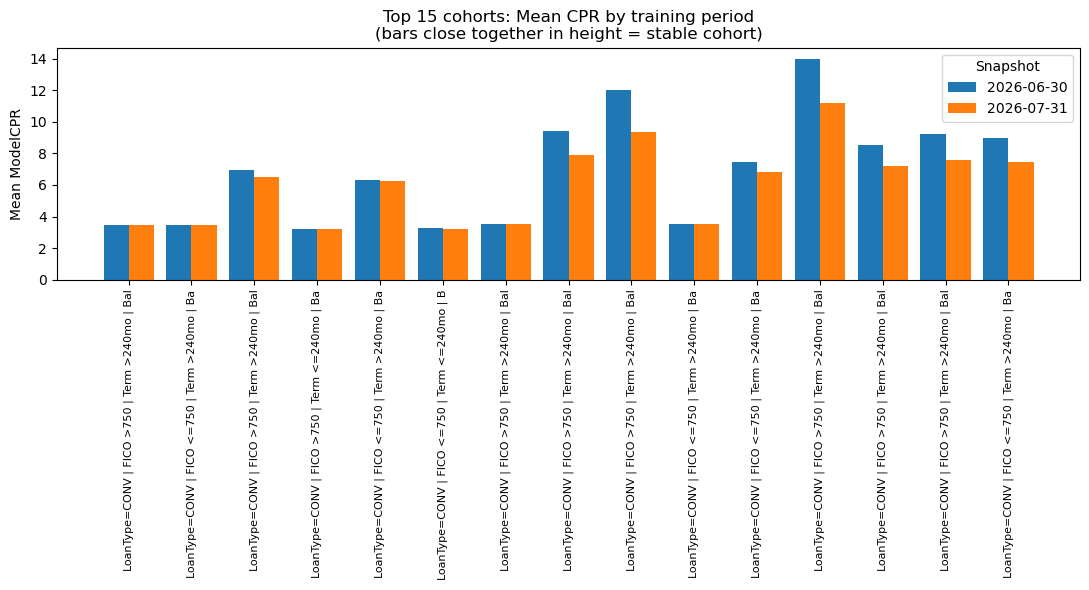

In [71]:
fig, ax = plt.subplots(figsize=(11, 6))
period_cols = [c for c in period_pivot.columns if c not in ("Range_across_periods", "N")]
x = np.arange(len(period_pivot))
width = 0.8 / len(period_cols)
for i, period in enumerate(sorted(period_cols)):
    ax.bar(x + i * width, period_pivot[period], width=width, label=period)
ax.set_xticks(x + width * (len(period_cols) - 1) / 2)
ax.set_xticklabels([r[:45] for r in period_pivot.index], rotation=90, fontsize=8)
ax.set_ylabel("Mean ModelCPR")
ax.set_title("Top 15 cohorts: Mean CPR by training period\n(bars close together in height = stable cohort)")
ax.legend(title="Snapshot")
plt.tight_layout()
plt.show()


## 9. Final Cohort Table & Reusable Scoring Function

`assign_cohort(int_rate, remaining_term_months, prin_bal, loan_type, market_rate)` returns the LoanType, RemainingTermBand, PrinBalGroup and RateSpreadGroup key. It uses the same LoanType normalization, right-inclusive term boundaries and learned merge maps as cohort construction. Market rate must come from the loan's own snapshot.

Coverage checks test every band combination, exact 240/360-month boundaries, missing terms, LoanType normalization and sampled scoring parity. Unseen fixed segments receive a rule but no fabricated CPR estimate.

Revised definitions, balance/spread maps, configuration and evaluation metrics are exported to `cohort_artifacts_FHA_VA_Oct26/`. The legacy v2 files are not overwritten. The existing companion validation notebook uses a different schema and must be updated before consuming these revised artifacts.

In [72]:
upb_by_key = df_b.groupby(KEYS, observed=True)["PrinBal"].sum().rename("UPB").reset_index()
final_display = final_cohorts.rename(columns={"RateSpreadBand": "RateSpreadGroup"}).merge(
    upb_by_key, on=KEYS, how="left", validate="one_to_one")
final_display["UPB"] = final_display["UPB"].fillna(0)
final_display = final_display.sort_values("N", ascending=False).reset_index(drop=True)
final_display["PrinBalRange"] = final_display["PrinBalGroup"].apply(
    lambda value: simplify_merged_label(value, PRINBAL_LABELS, PRINBAL_EDGE_TEXT))
final_display["RateSpreadRange"] = final_display["RateSpreadGroup"].apply(
    lambda value: simplify_merged_label(value, SPREAD_LABELS, SPREAD_EDGE_TEXT))
final_display["Rule"] = (
    "LoanType=" + final_display["LoanType"].astype(str)
    + " | FICOOrig " + final_display["FICOOrigBand"].astype(str)
    + " | RemainingTerm " + final_display["RemainingTermBand"].astype(str)
    + " | PrinBal " + final_display["PrinBalRange"].astype(str)
    + " | RateSpread " + final_display["RateSpreadRange"].astype(str)
)
final_display["Extrapolated"] = final_display["N"].eq(0)
final_display["BelowCountFloor"] = final_display["N"].between(1, MIN_COHORT_N_FLOOR - 1)
final_display["Reliable"] = (final_display["N"] >= 2) & final_display["SE_Mean"].le(SE_MEAN_TARGET)
cols = ["Rule", "N", "UPB", "Mean_CPR", "Std_CPR", "SE_Mean", "CV", "Reliable", "BelowCountFloor", "Extrapolated"]
assert np.isclose(final_display["UPB"].sum(), df["PrinBal"].sum())
final_display[cols]

,Rule,N,UPB,Mean_CPR,Std_CPR,SE_Mean,CV,Reliable,BelowCountFloor,Extrapolated
0,LoanType=CONV | FICOOrig >750 | RemainingTerm ...,202060,4.705963e+10,3.486286,0.645593,0.001436,0.185181,True,False,False
1,LoanType=CONV | FICOOrig <=750 | RemainingTerm...,142456,3.138446e+10,3.481525,0.972818,0.002577,0.279423,True,False,False
2,LoanType=CONV | FICOOrig >750 | RemainingTerm ...,86196,2.119197e+10,6.697391,1.619682,0.005517,0.241838,True,False,False
3,LoanType=CONV | FICOOrig >750 | RemainingTerm ...,68102,9.417526e+09,3.187519,0.945469,0.003623,0.296616,True,False,False
4,LoanType=CONV | FICOOrig <=750 | RemainingTerm...,53987,1.213228e+10,6.276783,1.039562,0.004474,0.165620,True,False,False
...,...,...,...,...,...,...,...,...,...,...
111,LoanType=CONV | FICOOrig >750 | RemainingTerm ...,0,0.000000e+00,NaN,NaN,NaN,NaN,False,False,True
112,LoanType=FHA | FICOOrig >750 | RemainingTerm M...,0,0.000000e+00,NaN,NaN,NaN,NaN,False,False,True
113,LoanType=OTHERS | FICOOrig >750 | RemainingTer...,0,0.000000e+00,NaN,NaN,NaN,NaN,False,False,True
114,LoanType=OTHERS | FICOOrig <=750 | RemainingTe...,0,0.000000e+00,NaN,NaN,NaN,NaN,False,False,True


In [73]:
_populated = final_display.loc[~final_display["Extrapolated"]].copy()
unreliable = _populated.loc[
    ~_populated["Reliable"] | _populated["BelowCountFloor"] | _populated["CV"].gt(CV_FLAG_THRESHOLD),
    ["LoanType"] + cols
].sort_values("SE_Mean", ascending=False)
_upb_flagged_pct = unreliable["UPB"].sum() / _populated["UPB"].sum()
print(f"{len(unreliable)}/{len(_populated)} cohorts flagged by SE, count floor or CV; {_upb_flagged_pct:.1%} of pooled UPB.")
print("SE uses pooled observations; repeated monthly observations are not independent loans.")
unreliable

77/109 cohorts flagged by SE, count floor or CV; 51.2% of pooled UPB.
SE uses pooled observations; repeated monthly observations are not independent loans.


,LoanType,Rule,N,UPB,Mean_CPR,Std_CPR,SE_Mean,CV,Reliable,BelowCountFloor,Extrapolated
104,VA,LoanType=VA | FICOOrig >750 | RemainingTerm <=...,523,1.195570e+08,9.650880,7.940650,0.347220,0.822790,False,True,False
106,FHA,LoanType=FHA | FICOOrig >750 | RemainingTerm <...,240,2.949635e+07,3.683935,5.050420,0.326003,1.370931,False,True,False
103,VA,LoanType=VA | FICOOrig <=750 | RemainingTerm <...,595,1.043450e+08,4.904396,5.528395,0.226642,1.127232,True,True,False
88,FHA,LoanType=FHA | FICOOrig <=750 | RemainingTerm ...,2049,4.063851e+08,24.152173,10.107514,0.223292,0.418493,True,False,False
99,FHA,LoanType=FHA | FICOOrig >750 | RemainingTerm >...,1561,2.934223e+08,13.889680,8.775103,0.222101,0.631771,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...
22,FHA,LoanType=FHA | FICOOrig <=750 | RemainingTerm ...,9475,3.002359e+09,1.761694,0.575658,0.005914,0.326764,True,False,False
5,CONV,LoanType=CONV | FICOOrig <=750 | RemainingTerm...,50367,7.146162e+09,3.237359,0.827195,0.003686,0.255515,True,False,False
3,CONV,LoanType=CONV | FICOOrig >750 | RemainingTerm ...,68102,9.417526e+09,3.187519,0.945469,0.003623,0.296616,True,False,False
1,CONV,LoanType=CONV | FICOOrig <=750 | RemainingTerm...,142456,3.138446e+10,3.481525,0.972818,0.002577,0.279423,True,False,False


In [74]:
if len(unreliable):
    print("Flagged cohorts by LoanType:")
    print(unreliable["LoanType"].value_counts().to_string())
    print("Rare LoanType/term/FICO segments may remain below the count floor even after all balance/spread bands merge.")
    print("Keep these estimates flagged; neither the 240/360-month term boundaries nor the FICO=750 boundary is crossed.")
else:
    print("No populated cohorts are flagged.")

Flagged cohorts by LoanType:
LoanType
CONV      26
FHA       25
VA        22
OTHERS     4
Rare LoanType/term/FICO segments may remain below the count floor even after all balance/spread bands merge.
Keep these estimates flagged; neither the 240/360-month term boundaries nor the FICO=750 boundary is crossed.


In [75]:
DEFAULT_MARKET_RATE = float(period_summary.sort_values("Period")["Market_Rate"].iloc[-1])


def assign_cohort(int_rate, remaining_term_months, prin_bal, loan_type, market_rate, fico_orig):
    """Return the LoanType/term/FICO/balance/spread key; snapshot market_rate and original FICO are required."""
    category = normalize_loan_type(pd.Series([loan_type])).iloc[0]
    term = pd.to_numeric(pd.Series([remaining_term_months]), errors="coerce").iloc[0]
    term_band = "Missing" if pd.isna(term) or term < 0 else str(pd.cut(
        [term], bins=REMAININGTERM_EDGES, labels=REMAININGTERM_LABELS, include_lowest=True)[0])
    fico_band = str(fico_bands(pd.Series([fico_orig])).iloc[0])
    spread = int_rate - market_rate
    if not np.isfinite(spread) or not np.isfinite(prin_bal):
        raise ValueError("Finite interest rate, market rate and principal balance are required.")
    balance_band = str(pd.cut([prin_bal], bins=PRINBAL_EDGES, labels=PRINBAL_LABELS, include_lowest=True)[0])
    balance_group = prinbal_map_lookup[(category, term_band, fico_band, balance_band)]
    spread_band = str(pd.cut([spread], bins=SPREAD_EDGES, labels=SPREAD_LABELS, include_lowest=True)[0])
    spread_group = spread_map_lookup[(category, term_band, fico_band, balance_group, spread_band)]
    return category, term_band, fico_band, balance_group, spread_group


for _, row in df.head(5).iterrows():
    print(assign_cohort(row["IntRate"], row["RemainingTerm"], row["PrinBal"], row["LoanType"], row["Market_Rate"], row["FICOOrig"]))

('CONV', '<=240mo', '<=750', '<=150k | 150-250k | 250-400k | >400k', '(-2%, -1.75%] | (-1.75%, -1.5%] | (-1.5%, -1.25%] | (-1.25%, -1%] | (-1%, -0.75%]')
('CONV', '<=240mo', '<=750', '<=150k | 150-250k | 250-400k | >400k', '(-2%, -1.75%] | (-1.75%, -1.5%] | (-1.5%, -1.25%] | (-1.25%, -1%] | (-1%, -0.75%]')
('CONV', 'Missing', '<=750', '<=150k | 150-250k | 250-400k | >400k', '(-Inf, -2%] | (-2%, -1.75%] | (-1.75%, -1.5%] | (-1.5%, -1.25%] | (-1.25%, -1%] | (-1%, -0.75%] | (-0.75%, -0.5%] | (-0.5%, -0.25%] | (-0.25%, 0%] | (0%, +0.25%] | (+0.25%, +0.5%] | (+0.5%, +0.75%] | (+0.75%, +1%] | (+1%, +1.25%] | (+1.25%, +1.5%] | (+1.5%, +1.75%] | (+1.75%, +2%] | (+2%, +Inf]')
('CONV', '<=240mo', '<=750', '<=150k | 150-250k | 250-400k | >400k', '(-2%, -1.75%] | (-1.75%, -1.5%] | (-1.5%, -1.25%] | (-1.25%, -1%] | (-1%, -0.75%]')
('CONV', '<=240mo', '<=750', '<=150k | 150-250k | 250-400k | >400k', '(-Inf, -2%]')


In [77]:
from itertools import product

final_keys = set(map(tuple, final_display[KEYS].itertuples(index=False, name=None)))
checked = 0
for category, term_band, fico_band, balance_band, spread_band in product(
    LOAN_TYPES, TERM_LABELS, FICOORIG_LABELS, PRINBAL_LABELS, SPREAD_LABELS
):
    balance_group = prinbal_map_lookup[(category, term_band, fico_band, balance_band)]
    spread_group = spread_map_lookup[(category, term_band, fico_band, balance_group, spread_band)]
    assert (category, term_band, fico_band, balance_group, spread_group) in final_keys
    checked += 1

for _, row in df_b.sample(n=min(500, len(df_b)), random_state=42).iterrows():
    key = assign_cohort(row["IntRate"], row["RemainingTerm"], row["PrinBal"], row["LoanType"], row["Market_Rate"], row["FICOOrig"])
    assert key == tuple(row[KEYS])
assert REMAININGTERM_LABELS == ["<=240mo", ">240mo"]
for term, expected in [(240, "<=240mo"), (241, ">240mo"), (360, ">240mo"), (361, ">240mo"), (np.nan, "Missing"), (-1, "Missing")]:
    assert assign_cohort(7, term, 200000, "CONV-PMI", 6, 750)[0:3] == ("CONV", expected, "<=750")
for category in [None, "USDA", "", "OTHERS"]:
    assert assign_cohort(7, 240, 200000, category, 6, 751)[0] == "OTHERS"
for score, expected in [(750, "<=750"), (751, ">750"), (749, "<=750"), (849, ">750"),
                        (np.nan, "<=750"), (None, "<=750"), (300, "<=750"), (850, "<=750")]:
    assert assign_cohort(7, 240, 200000, "CONV", 6, score)[2] == expected
assert assign_cohort(7, 240, 200000, "CONV", 6, 750) != assign_cohort(7, 240, 200000, "CONV", 6, 751)
print(f"Full coverage: {checked} band combinations; 500 sampled scoring parity checks passed.")
print("Term/FICO boundaries, missing/sentinel FICO defaults and LoanType normalization passed.")
print(f"Extrapolated-only rules: {final_display['Extrapolated'].sum()} (estimates remain NaN).")

Full coverage: 1728 band combinations; 500 sampled scoring parity checks passed.
Term/FICO boundaries, missing/sentinel FICO defaults and LoanType normalization passed.
Extrapolated-only rules: 7 (estimates remain NaN).


## 10. Business Summary Dashboard

A one-glance view built for a **non-technical business audience**: how many loans/dollars are
covered, how confident we are in the numbers, and simple charts showing which segments prepay
fast vs. slow. Everything below is computed fresh from whatever training data is currently
loaded, so it never goes stale.


In [78]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)
pd.set_option('display.max_columns', None)

_pop = final_display[final_display["N"] > 0].copy()
total_upb = _pop["UPB"].sum()
reliable_mask = _pop["SE_Mean"] <= SE_MEAN_TARGET
reliable_upb_pct = _pop.loc[reliable_mask, "UPB"].sum() / total_upb
reliable_cohort_pct = reliable_mask.mean()

# New metrics
_total_n = _pop["N"].sum()
wavg_cv  = (_pop["N"] * _pop["CV"]).sum()  / _total_n
wavg_std = (_pop["N"] * _pop["Std_CPR"]).sum() / _total_n
loan_coverage_pct = _total_n / len(df)   # % of all training loans captured by populated cohorts


def _flag_high(v, green_min, yellow_min):
    return "GREEN" if v >= green_min else ("YELLOW" if v >= yellow_min else "RED")


def _flag_low(v, green_max, yellow_max):
    return "GREEN" if v <= green_max else ("YELLOW" if v <= yellow_max else "RED")


_period_lo_str = period_summary["Period"].min()
_period_hi_str = period_summary["Period"].max()

business_scorecard = pd.DataFrame([
    {"Metric": "Active loans used to build cohorts",
     "Value": f"{len(df):,}", "Status": "-"},
    {"Metric": "Training snapshots pooled",
     "Value": f"{len(TRAIN_SRCS)} months ({_period_lo_str} to {_period_hi_str})", "Status": "-"},
    {"Metric": "Final cohorts (populated)",
     "Value": f"{len(_pop)}", "Status": "-"},
    {"Metric": "Loan Coverage % in Cohorts",
     "Value": f"{loan_coverage_pct:.1%}",
     "Status": _flag_high(loan_coverage_pct, 0.99, 0.95)},
    {"Metric": "Variance explained by cohorts",
     "Value": f"{variance_explained:.1%}",
     "Status": _flag_high(variance_explained, 0.70, 0.50)},
    {"Metric": "Weighted Avg Std Deviation (Std_CPR)",
     "Value": f"{wavg_std:.4f} CPR pts", "Status": "-"},
    {"Metric": "Weighted Avg CV",
     "Value": f"{wavg_cv:.4f}",
     "Status": _flag_low(wavg_cv, 0.30, 0.50)},
    {"Metric": "Avg cohort CPR spread across training months (stability)",
     "Value": f"{avg_range_weighted:.2f} CPR pts",
     "Status": _flag_low(avg_range_weighted, 1.0, 2.0)},
])
print("COHORT BUSINESS SCORECARD")
print(business_scorecard.to_string(index=False))


COHORT BUSINESS SCORECARD
                                                  Metric                               Value Status
                      Active loans used to build cohorts                           1,210,118      -
                               Training snapshots pooled 2 months (2026-06-30 to 2026-07-31)      -
                               Final cohorts (populated)                                 109      -
                              Loan Coverage % in Cohorts                              100.0%  GREEN
                           Variance explained by cohorts                               75.2%  GREEN
                    Weighted Avg Std Deviation (Std_CPR)                      1.7233 CPR pts      -
                                         Weighted Avg CV                              0.2652  GREEN
Avg cohort CPR spread across training months (stability)                        0.77 CPR pts  GREEN


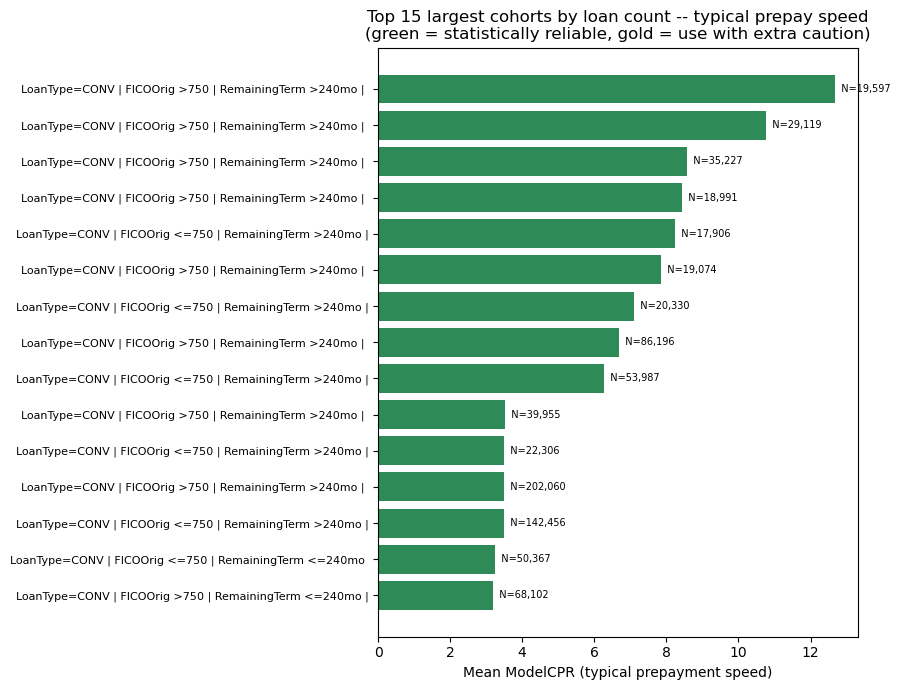

In [80]:
top_n = 15
top_cohorts_viz = _pop.sort_values("N", ascending=False).head(top_n).sort_values("Mean_CPR")
fig, ax = plt.subplots(figsize=(9, 7))
bar_colors = np.where(top_cohorts_viz["SE_Mean"] <= SE_MEAN_TARGET, "seagreen", "goldenrod")
ax.barh(range(len(top_cohorts_viz)), top_cohorts_viz["Mean_CPR"], color=bar_colors)
ax.set_yticks(range(len(top_cohorts_viz)))
ax.set_yticklabels([r[:55] for r in top_cohorts_viz["Rule"]], fontsize=8)
ax.set_xlabel("Mean ModelCPR (typical prepayment speed)")
ax.set_title(f"Top {top_n} largest cohorts by loan count -- typical prepay speed\n"
             "(green = statistically reliable, gold = use with extra caution)")
for i, (n_val, upb_val) in enumerate(zip(top_cohorts_viz["N"], top_cohorts_viz["UPB"])):
    ax.text(top_cohorts_viz["Mean_CPR"].iloc[i], i, f"  N={n_val:,.0f}", va="center", fontsize=7)
plt.tight_layout()
plt.show()


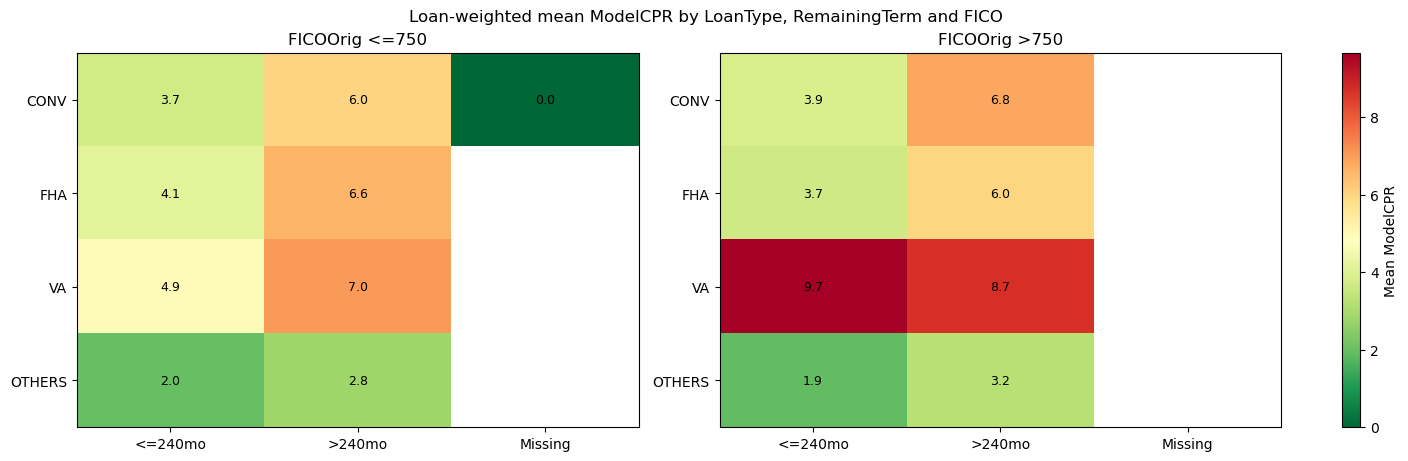

In [81]:
heat_by_fico = df_b.groupby(BASE_KEYS, observed=True)["ModelCPR"].mean()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
color_min, color_max = heat_by_fico.min(), heat_by_fico.max()
for axis, fico_band in zip(axes, FICOORIG_LABELS):
    heat = heat_by_fico.xs(fico_band, level="FICOOrigBand").unstack("RemainingTermBand")
    heat = heat.reindex(index=LOAN_TYPES, columns=TERM_LABELS)
    image = axis.imshow(heat.values, cmap="RdYlGn_r", aspect="auto", vmin=color_min, vmax=color_max)
    axis.set_xticks(range(len(heat.columns)))
    axis.set_xticklabels(heat.columns)
    axis.set_yticks(range(len(heat.index)))
    axis.set_yticklabels(heat.index)
    for row_index in range(heat.shape[0]):
        for column_index in range(heat.shape[1]):
            value = heat.iloc[row_index, column_index]
            if np.isfinite(value):
                axis.text(column_index, row_index, f"{value:.1f}", ha="center", va="center", fontsize=9)
    axis.set_title(f"FICOOrig {fico_band}")
fig.suptitle("Loan-weighted mean ModelCPR by LoanType, RemainingTerm and FICO")
fig.colorbar(image, ax=axes.tolist(), label="Mean ModelCPR")
plt.show()

In [79]:
n_periods = len(TRAIN_SRCS)
period_lo = period_summary["Period"].min()
period_hi = period_summary["Period"].max()
summary_text = f"""
BUSINESS SUMMARY
------------------------------------------------------------------
{len(df):,} active-loan observations; {n_distinct_loans:,} distinct loans;
{n_periods} snapshots ({period_lo} to {period_hi}).

Cohort rules use normalized LoanType, RemainingTerm (<=240 / >240 months),
FICOOrig (<=750 / >750), principal balance and rate spread.
FICO buckets are required business rules regardless of CART importance and are not merged.
Missing/sentinel FICO values default to <=750.
Investor category and loan age are not rule inputs; LTV and ARM remain tree candidates.

{len(_pop)} populated cohorts explain {variance_explained:.1%} of training CPR variance.
{reliable_cohort_pct:.1%} meet the SE precision target, covering {reliable_upb_pct:.1%}
of pooled UPB. {int(final_display['BelowCountFloor'].sum())} populated cohorts remain below
the count floor; {int(final_display['Extrapolated'].sum())} rules have no training estimates.

Average training-period mean-CPR range: {avg_range_weighted:.2f} CPR points.
Held-out-loan metrics are reported separately above; this is not out-of-time validation.
SE is observation-based and does not adjust for repeated observations of the same loan.
"""
print(summary_text)


BUSINESS SUMMARY
------------------------------------------------------------------
1,210,118 active-loan observations; 626,132 distinct loans;
2 snapshots (2026-06-30 to 2026-07-31).

Cohort rules use normalized LoanType, RemainingTerm (<=240 / >240 months),
FICOOrig (<=750 / >750), principal balance and rate spread.
FICO buckets are required business rules regardless of CART importance and are not merged.
Missing/sentinel FICO values default to <=750.
Investor category and loan age are not rule inputs; LTV and ARM remain tree candidates.

109 populated cohorts explain 75.2% of training CPR variance.
98.2% meet the SE precision target, covering 100.0%
of pooled UPB. 7 populated cohorts remain below
the count floor; 7 rules have no training estimates.

Average training-period mean-CPR range: 0.77 CPR points.
Held-out-loan metrics are reported separately above; this is not out-of-time validation.
SE is observation-based and does not adjust for repeated observations of the same loan.



## 11. Export Revised Cohort Artifacts

Exports use schema version 3 in `cohort_artifacts_FHA_VA_Oct26/`, leaving legacy investor/age/FICO v2 artifacts untouched. The config records LoanType normalization, fixed 240/360-month term bands, missing-term behavior, right-inclusive interval semantics, merge parameters and evaluation metadata. Infinite endpoints are encoded as strings for strict JSON.

CSV and JSON round-trip checks verify coverage and totals. The older companion validation notebook is not compatible with this schema without corresponding changes.

In [82]:
from pathlib import Path

ARTIFACT_DIR = Path("cohort_artifacts_FHA_VA_Oct26")
ARTIFACT_DIR.mkdir(exist_ok=True)
export_cols = KEYS + ["PrinBalRange", "RateSpreadRange", "Rule", "N", "UPB", "Mean_CPR", "Std_CPR",
                      "SE_Mean", "CV", "Reliable", "BelowCountFloor", "Extrapolated"]
final_display[export_cols].to_csv(ARTIFACT_DIR / "cohort_definitions.csv", index=False)
prinbal_map.to_csv(ARTIFACT_DIR / "prinbal_map.csv", index=False)
spread_map.to_csv(ARTIFACT_DIR / "spread_map.csv", index=False)
term_ablation.to_csv(ARTIFACT_DIR / "remainingterm_tree_ablation.csv")
cohort_holdout_metrics.to_csv(ARTIFACT_DIR / "cohort_holdout_metrics.csv", index=False)
print(f"Saved revised cohort artifacts to {ARTIFACT_DIR.resolve()}")
print("Legacy v2 files are unchanged. Their validation notebook needs a schema update before using these artifacts.")

Saved revised cohort artifacts to C:\Users\kanshash\OneDrive - Onity Group Inc\Desktop\Dev\B2B_pricing\cohort_artifacts_FHA_VA_Oct26
Legacy v2 files are unchanged. Their validation notebook needs a schema update before using these artifacts.


In [83]:
import json


def json_edges(edges):
    return ["-inf" if np.isneginf(edge) else "inf" if np.isposinf(edge) else float(edge) for edge in edges]


cohort_config = {
    "schema_version": 4,
    "generated_from": TRAIN_SRCS,
    "training_periods": period_summary["Period"].tolist(),
    "training_market_rates": dict(zip(period_summary["Period"], period_summary["Market_Rate"].round(4))),
    "cohort_keys": KEYS,
    "loan_types": LOAN_TYPES,
    "loan_type_normalization": {"CONV-PMI": "CONV", "keep": ["CONV", "FHA", "VA"], "otherwise": "OTHERS", "strip_and_upper": True},
    "eligibility_note": "Active loans only; existing PLS and seller exclusions retained. InvestorCatgy is used for eligibility only.",
    "excluded_rule_features": ["InvestorCatgy", "InvestorGroup", "LoanAge", "LTVOrig", "ArmFlag"],
    "rate_spread_note": "RateSpread = IntRate - row-level Market_Rate. Scoring requires the loan's snapshot market rate.",
    "edge_encoding": "Convert the strings '-inf'/'inf' to floating infinities; numeric edges are right-inclusive.",
    "remainingterm_edges": json_edges(REMAININGTERM_EDGES),
    "remainingterm_labels": REMAININGTERM_LABELS,
    "remainingterm_missing_label": "Missing",
    "remainingterm_note": "User-selected <=240 / >240-month buckets; negative/missing term maps to Missing. Term bands are not merged.",
    "remainingterm_significance_passed": USE_REMAINING_TERM,
    "remainingterm_importance": float(imp6["RemainingTerm"]),
    "ficoorig_edges": json_edges(FICOORIG_EDGES),
    "ficoorig_labels": FICOORIG_LABELS,
    "ficoorig_missing_label": "<=750",
    "ficoorig_note": "User-required fixed split at 750, regardless of CART importance. Missing/non-numeric or sentinel scores <=300/>=850 default to <=750. FICO bands are not merged.",
    "prinbal_edges": json_edges(PRINBAL_EDGES), "prinbal_labels": PRINBAL_LABELS,
    "spread_edges": json_edges(SPREAD_EDGES), "spread_labels": SPREAD_LABELS,
    "se_mean_target": SE_MEAN_TARGET, "std_inflation_max": STD_INFLATION_MAX,
    "min_cohort_n_floor": MIN_COHORT_N_FLOOR, "mean_merge_tol": MEAN_MERGE_TOL,
    "overall_mean_train": float(overall_mean), "overall_std_train": float(overall_std),
    "variance_explained_train": float(variance_explained),
    "cohorts_total_train": int(len(final_cohorts)),
    "cohorts_populated_train": int(final_cohorts["N"].gt(0).sum()),
    "n_train_total": int(len(df)), "n_train_distinct_loans": int(n_distinct_loans),
    "avg_cross_period_cpr_range_train": float(avg_range_weighted),
    "reliability_note": "SE is observation-based; repeat monthly observations are not independent. Count floor is not guaranteed for rare LoanType/term/FICO segments.",
}
with (ARTIFACT_DIR / "cohort_bands_config.json").open("w") as output:
    json.dump(cohort_config, output, indent=2, allow_nan=False)
with (ARTIFACT_DIR / "cohort_bands_config.json").open() as source:
    saved_config = json.load(source)
assert [float(edge) for edge in saved_config["remainingterm_edges"]] == REMAININGTERM_EDGES
assert saved_config["remainingterm_labels"] == ["<=240mo", ">240mo"]
assert [float(edge) for edge in saved_config["ficoorig_edges"]] == FICOORIG_EDGES
assert saved_config["ficoorig_labels"] == FICOORIG_LABELS
assert saved_config["cohort_keys"] == KEYS
saved_balance_map = pd.read_csv(ARTIFACT_DIR / "prinbal_map.csv")
saved_spread_map = pd.read_csv(ARTIFACT_DIR / "spread_map.csv")
saved_definitions = pd.read_csv(ARTIFACT_DIR / "cohort_definitions.csv")
saved_scored = add_bands(df.sample(500, random_state=42)).merge(
    saved_balance_map, on=BASE_KEYS + ["PrinBalBand"], how="left", validate="many_to_one").merge(
    saved_spread_map, on=BASE_KEYS + ["PrinBalGroup", "RateSpreadBand"], how="left", validate="many_to_one")
assert saved_scored[KEYS].notna().all().all()
assert set(map(tuple, saved_scored[KEYS].itertuples(index=False, name=None))).issubset(
    set(map(tuple, saved_definitions[KEYS].itertuples(index=False, name=None))))
assert saved_definitions["N"].sum() == len(df)
assert set(saved_definitions["FICOOrigBand"]) == set(FICOORIG_LABELS)
print("Config and FICO-aware CSV round-trip checks passed; strict JSON exported with schema_version=4.")

Config and FICO-aware CSV round-trip checks passed; strict JSON exported with schema_version=4.


## 12. Appendix: SE-Target Sensitivity

Sweep SE_MEAN_TARGET using the same two-stage cohort builder. LoanType categories and the 240/360-month term boundaries remain fixed. The inflation guard can block merges, and rare fixed segments may remain imprecise regardless of merging. Compare cohort counts, precision-target compliance and training variance explained without assuming monotonic improvements.

In [84]:
def sweep_metrics(se_target=SE_MEAN_TARGET, min_floor=MIN_COHORT_N_FLOOR):
    _, cohorts, _, _ = build_cohorts(df, se_target=se_target, min_floor=min_floor)
    populated = cohorts.loc[cohorts["N"] > 0]
    count = populated["N"].sum()
    within_variance = (populated["N"] * populated["Std_CPR"] ** 2).sum() / count
    return {
        "SE_MEAN_TARGET": se_target, "MIN_COHORT_N_FLOOR": min_floor,
        "Cohorts_total": len(cohorts), "Cohorts_populated": len(populated),
        "Reliable_cohorts": int(populated["SE_Mean"].le(se_target).sum()),
        "Reliable_%": populated["SE_Mean"].le(se_target).mean(),
        "Loan_wtd_SE": (populated["N"] * populated["SE_Mean"]).sum() / count,
        "Loan_wtd_avg_CV": (populated["N"] * populated["CV"]).sum() / count,
        "Pct_cohorts_CV_gt_0.20": populated["CV"].gt(0.20).mean(),
        "Pct_cohorts_CV_gt_0.35": populated["CV"].gt(0.35).mean(),
        "Var_explained": 1 - within_variance / overall_std ** 2,
        "Below_floor": int(populated["N"].lt(min_floor).sum()),
    }


sensitivity = pd.DataFrame([sweep_metrics(se_target=target) for target in [0.05, 0.10, 0.15, 0.25, 0.50, 1.00]])
print("Sensitivity to the SE target; LoanType, the 240-month term cut and FICO=750 remain fixed.")
sensitivity.round(4)

Sensitivity to the SE target; LoanType, the 240-month term cut and FICO=750 remain fixed.


,SE_MEAN_TARGET,MIN_COHORT_N_FLOOR,Cohorts_total,Cohorts_populated,Reliable_cohorts,Reliable_%,Loan_wtd_SE,Loan_wtd_avg_CV,Pct_cohorts_CV_gt_0.20,Pct_cohorts_CV_gt_0.35,Var_explained,Below_floor
0,0.05,1500,102,95,72,0.7579,0.0156,0.2594,0.9053,0.2526,0.7645,7
1,0.10,1500,115,108,90,0.8333,0.0174,0.2639,0.8889,0.3056,0.7565,7
2,0.15,1500,116,109,101,0.9266,0.0177,0.2652,0.8899,0.3211,0.7519,7
3,0.25,1500,116,109,107,0.9817,0.0177,0.2652,0.8899,0.3211,0.7519,7
4,0.50,1500,116,109,109,1.0000,0.0177,0.2652,0.8899,0.3211,0.7519,7
5,1.00,1500,116,109,109,1.0000,0.0177,0.2652,0.8899,0.3211,0.7519,7


## 13. Count-Floor Sensitivity

Sweep MIN_COHORT_N_FLOOR while holding the other merge settings fixed. The same two-stage builder is used for the main run and both sensitivity sweeps.

Compare loan-weighted CV, cohort counts, SE-target compliance, unresolved below-floor cohorts and variance explained. The floor triggers forced merges; it does not guarantee every final cohort reaches that size, because merges do not cross LoanType or the requested term bands. Conclusions are derived from this run and do not presume that any tested floor reaches 100% precision-target compliance.

In [85]:
_floor_grid = [250, 500, 750, 1000, 1250, 1500, 2000, 2500, 3000, 4000, 5000, 7500, 10000]
n_floor_sweep = pd.DataFrame([sweep_metrics(min_floor=floor) for floor in _floor_grid])
print("Count-floor sensitivity; merges never cross LoanType, the 240-month term cut or FICO=750.")
display(n_floor_sweep.round(4))
_cur = n_floor_sweep.loc[n_floor_sweep["MIN_COHORT_N_FLOOR"] == MIN_COHORT_N_FLOOR].iloc[0]
print(f"Current floor: {MIN_COHORT_N_FLOOR}; cohorts: {int(_cur['Cohorts_populated'])}; "
      f"weighted CV: {_cur['Loan_wtd_avg_CV']:.4f}; variance explained: {_cur['Var_explained']:.1%}")

Count-floor sensitivity; merges never cross LoanType, the 240-month term cut or FICO=750.


,SE_MEAN_TARGET,MIN_COHORT_N_FLOOR,Cohorts_total,Cohorts_populated,Reliable_cohorts,Reliable_%,Loan_wtd_SE,Loan_wtd_avg_CV,Pct_cohorts_CV_gt_0.20,Pct_cohorts_CV_gt_0.35,Var_explained,Below_floor
0,0.25,250,200,193,177,0.9171,0.0202,0.2455,0.8705,0.2591,0.7925,3
1,0.25,500,167,160,149,0.9312,0.0195,0.2539,0.8938,0.2812,0.7838,4
2,0.25,750,149,142,136,0.9577,0.0186,0.2554,0.8803,0.2676,0.7756,7
3,0.25,1000,137,130,127,0.9769,0.0182,0.2586,0.8769,0.2769,0.7643,7
4,0.25,1250,128,121,119,0.9835,0.0178,0.2605,0.8843,0.2975,0.7626,7
5,0.25,1500,116,109,107,0.9817,0.0177,0.2652,0.8899,0.3211,0.7519,7
6,0.25,2000,102,95,93,0.9789,0.0176,0.2816,0.9053,0.3684,0.7279,7
7,0.25,2500,87,80,78,0.9750,0.0175,0.3169,0.8875,0.4125,0.6837,8
8,0.25,3000,84,77,75,0.9740,0.0172,0.3137,0.8701,0.4026,0.6796,8
9,0.25,4000,76,69,67,0.9710,0.0164,0.3376,0.8696,0.3913,0.6734,8


Current floor: 1500; cohorts: 109; weighted CV: 0.2652; variance explained: 75.2%


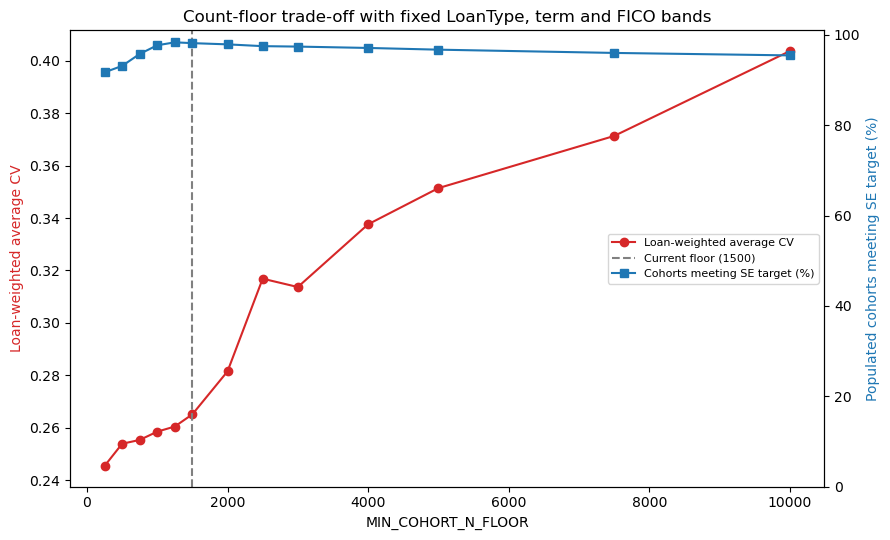

In [86]:
fig, ax1 = plt.subplots(figsize=(9, 5.5))
ax1.plot(n_floor_sweep["MIN_COHORT_N_FLOOR"], n_floor_sweep["Loan_wtd_avg_CV"],
         marker="o", color="tab:red", label="Loan-weighted average CV")
ax1.axvline(MIN_COHORT_N_FLOOR, color="gray", linestyle="--", label=f"Current floor ({MIN_COHORT_N_FLOOR})")
ax1.set_xlabel("MIN_COHORT_N_FLOOR")
ax1.set_ylabel("Loan-weighted average CV", color="tab:red")
ax2 = ax1.twinx()
ax2.plot(n_floor_sweep["MIN_COHORT_N_FLOOR"], n_floor_sweep["Reliable_%"] * 100,
         marker="s", color="tab:blue", label="Cohorts meeting SE target (%)")
ax2.set_ylabel("Populated cohorts meeting SE target (%)", color="tab:blue")
ax2.set_ylim(0, 101)
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc="center right", fontsize=8)
ax1.set_title("Count-floor trade-off with fixed LoanType, term and FICO bands")
plt.tight_layout()
plt.show()

In [ ]:
n_floor_sweep["CV_change_vs_prev"] = n_floor_sweep["Loan_wtd_avg_CV"].diff()
n_floor_sweep["Cohorts_lost_vs_prev"] = -n_floor_sweep["Cohorts_populated"].diff()
display(n_floor_sweep[["MIN_COHORT_N_FLOOR", "Reliable_%", "Loan_wtd_avg_CV", "Cohorts_populated",
                       "Below_floor", "CV_change_vs_prev", "Cohorts_lost_vs_prev"]].round(4))
_fully_reliable = n_floor_sweep.loc[n_floor_sweep["Reliable_%"] >= 1.0]
if _fully_reliable.empty:
    print("No tested count floor achieves 100% precision-target compliance.")
    print("Rare LoanType/term/FICO segments cannot be repaired by merging only balance and spread bands.")
else:
    _min_reliable_floor = int(_fully_reliable["MIN_COHORT_N_FLOOR"].min())
    print(f"Smallest tested floor achieving 100% precision-target compliance: {_min_reliable_floor}")
print(f"Current floor {MIN_COHORT_N_FLOOR}: {_cur['Reliable_%']:.1%} meet the SE target; "
      f"{int(_cur['Below_floor'])} populated cohorts remain below the count floor.")
print("The floor is a merge trigger, not a guarantee of independent-loan precision or minimum final size.")

,MIN_COHORT_N_FLOOR,Reliable_%,Loan_wtd_avg_CV,Cohorts_populated,Below_floor,CV_change_vs_prev,Cohorts_lost_vs_prev
0,250,0.9171,0.2455,193,3,NaN,NaN
1,500,0.9312,0.2539,160,4,0.0085,33.0
2,750,0.9577,0.2554,142,7,0.0015,18.0
3,1000,0.9769,0.2586,130,7,0.0032,12.0
4,1250,0.9835,0.2605,121,7,0.0020,9.0
5,1500,0.9817,0.2652,109,7,0.0047,12.0
6,2000,0.9789,0.2816,95,7,0.0164,14.0
7,2500,0.9750,0.3169,80,8,0.0353,15.0
8,3000,0.9740,0.3137,77,8,-0.0032,3.0
9,4000,0.9710,0.3376,69,8,0.0239,8.0


No tested count floor achieves 100% precision-target compliance.
Rare LoanType/term/FICO segments cannot be repaired by merging only balance and spread bands.
Current floor 1500: 98.2% meet the SE target; 7 populated cohorts remain below the count floor.
The floor is a merge trigger, not a guarantee of independent-loan precision or minimum final size.


: 